# Data Integration: Pothole Work Orders × Cuaca NYC

**Input** (hasil `data_cleaning.ipynb`):
| File | Level | Periode |
|---|---|---|
| `output/pothole_clean.parquet` | 1 baris = 1 work order | 2010–2026 |
| `output/weather_clean.csv` | 1 baris = 1 hari (NYC) | 2018–2024 |

**Tujuan:** menggabungkan kedua sumber menjadi satu tabel **1 baris = 1 hari × 1 borough**, lalu mendeteksi dan membuang **atribut redundan**.

Notebook ini mengikuti 4 masalah utama integrasi data:

| Masalah integrasi | Bagian |
|---|---|
| 1. **Entity identification**: menyamakan kunci, tipe, dan granularitas | 2–4 |
| 2. **Tuple duplication**: memastikan tidak ada baris ganda setelah merge | 6 |
| 3. **Data value conflict**: satuan dan nilai yang bertentangan antar sumber | 6 |
| 4. **Redundancy & correlation analysis**: korelasi, kovarians, VIF, chi-square | 7–9 |

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)   # VIF sangat besar pada fitur kolinear sempurna
warnings.filterwarnings("ignore", module="statsmodels")      # peringatan matriks singular saat VIF sebelum drop
warnings.filterwarnings("ignore", message="The design matrix is poorly conditioned")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:,.3f}".format)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.titleweight": "bold"})

OUT_DIR, FIG_DIR = Path("output"), Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

BORO_NAME = {"B": "Brooklyn", "M": "Manhattan", "Q": "Queens", "S": "Staten Island", "X": "Bronx"}

## 1. Load Data Hasil Cleaning

In [2]:
pothole = pd.read_parquet(OUT_DIR / "pothole_clean.parquet")
weather = pd.read_csv(OUT_DIR / "weather_clean.csv", parse_dates=["date"])
N_CLEAN = len(pothole)

print("pothole:", pothole.shape, "| periode", pothole["RptDate"].min().date(), "s/d", pothole["RptDate"].max().date())
print("weather:", weather.shape, "| periode", weather["date"].min().date(), "s/d", weather["date"].max().date())

pothole: (400961, 27) | periode 2010-01-01 s/d 2026-08-29
weather: (2557, 7) | periode 2018-01-01 s/d 2024-12-31


## 2. Entity Identification: Menyamakan Kunci & Tipe

| Aspek | Pothole | Cuaca | Penyelesaian |
|---|---|---|---|
| Nama kolom tanggal | `RptDate` | `date` | Rename `RptDate` → `date` |
| Tipe tanggal | `datetime64` (sudah di-normalize) | `datetime64` | Dicek sama persis |
| Granularitas | per work order | per hari | Agregasi pothole ke per hari × borough (bagian 4) |
| Cakupan lokasi | 5 borough | 1 titik (NYC) | Cuaca yang sama dipakai untuk kelima borough (**asumsi**, dicatat sebagai keterbatasan) |
| Cakupan waktu | 2010–2026 | 2018–2024 | Filter ke irisan periode (bagian 3) |

In [3]:
pothole = pothole.rename(columns={"RptDate": "date"})
print("dtype tanggal  pothole:", pothole["date"].dtype, "| weather:", weather["date"].dtype)
print("Semua tanggal tanpa komponen jam:",
      (pothole["date"] == pothole["date"].dt.normalize()).all(),
      (weather["date"] == weather["date"].dt.normalize()).all())
print("Kode borough:", sorted(pothole["Boro"].unique().tolist()))

dtype tanggal  pothole: datetime64[us] | weather: datetime64[us]
Semua tanggal tanpa komponen jam: True True
Kode borough: ['B', 'M', 'Q', 'S', 'X']


## 3. Menyamakan Cakupan Waktu

Kedua sumber punya cakupan waktu berbeda, sehingga integrasi hanya bisa dilakukan pada **irisannya**. Rentang irisan ditentukan **otomatis** dari data (`weather["date"].min()/max()`), bukan diketik manual, agar tetap benar bila file cuaca diperbarui.

In [4]:
cov = pd.DataFrame({
    "sumber": ["Pothole (hasil cleaning)", "Cuaca (Open-Meteo)"],
    "mulai":  [pothole["date"].min().date(), weather["date"].min().date()],
    "selesai":[pothole["date"].max().date(), weather["date"].max().date()],
    "jumlah baris": [len(pothole), len(weather)],
})
display(cov)

# Cek file cuaca: benar-benar harian penuh tanpa bolong?
hari_penuh = pd.date_range(weather["date"].min(), weather["date"].max(), freq="D")
print("Hari kalender di rentang cuaca:", len(hari_penuh),
      "| baris file cuaca:", len(weather),
      "| tanggal bolong:", len(hari_penuh.difference(weather["date"])),
      "| duplikat:", weather["date"].duplicated().sum())

,sumber,mulai,selesai,jumlah baris
0,Pothole (hasil cleaning),2010-01-01,2026-08-29,400961
1,Cuaca (Open-Meteo),2018-01-01,2024-12-31,2557


Hari kalender di rentang cuaca: 2557 | baris file cuaca: 2557 | tanggal bolong: 0 | duplikat: 0


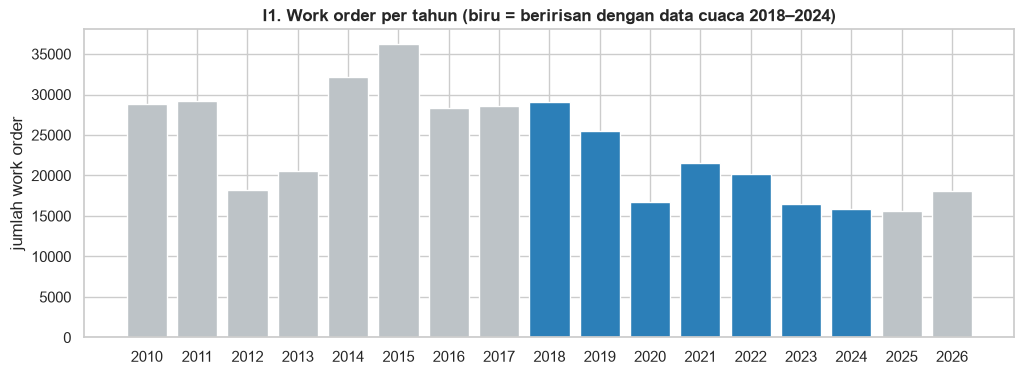

Difilter ke 2018-01-01 s/d 2024-12-31: 400,961 → 145,279 work order
  dibuang karena SEBELUM 2018: 221,879 (55.3%)
  dibuang karena SESUDAH 2024 : 33,803 (8.4%)
  total dibuang                : 255,682 (63.8%)


In [5]:
START, END = weather["date"].min(), weather["date"].max()

per_year = pothole["date"].dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 4))
colors = ["#2c7fb8" if START.year <= y <= END.year else "#bdc3c7" for y in per_year.index]
ax.bar(per_year.index.astype(str), per_year.values, color=colors)
ax.set_ylabel("jumlah work order")
ax.set_title(f"I1. Work order per tahun (biru = beririsan dengan data cuaca {START.year}–{END.year})")
savefig("I1_period_overlap")
plt.show()

before = len(pothole)
sebelum_start = (pothole["date"] < START).sum()
sesudah_end   = (pothole["date"] > END).sum()
pothole = pothole[pothole["date"].between(START, END)].copy()
print(f"Difilter ke {START.date()} s/d {END.date()}: {before:,} → {len(pothole):,} work order")
print(f"  dibuang karena SEBELUM {START.year}: {sebelum_start:,} ({sebelum_start/before*100:.1f}%)")
print(f"  dibuang karena SESUDAH {END.year} : {sesudah_end:,} ({sesudah_end/before*100:.1f}%)")
print(f"  total dibuang                : {before - len(pothole):,} ({(before-len(pothole))/before*100:.1f}%)")

**Catatan keterbatasan (penting).** Filter ini membuang **±64% work order hasil cleaning**, karena file cuaca yang tersedia hanya mencakup 2018–2024 sedangkan data pothole membentang 2010–2026.

Ini adalah batas **file cuaca yang diunduh**, bukan batas sumbernya: Open-Meteo Historical Weather API menyediakan data sejak 1940. Jadi cakupan analisis bisa diperluas dengan mengunduh ulang cuaca untuk rentang penuh 2010–2026, tanpa mengubah satu baris pun kode di notebook ini (rentang dihitung otomatis dari file cuaca).

Data pothole di luar periode **tidak dihapus permanen**: `output/pothole_clean.parquet` tetap menyimpan seluruh 400.961 baris (2010–2026). Pembatasan hanya berlaku pada tabel gabungan, karena baris tanpa pasangan data cuaca tidak bisa dipakai untuk analisis hubungan cuaca–pothole.

## 4. Agregasi Pothole: Work Order → Hari × Borough

| Fitur | Arti |
|---|---|
| `n_reports` | Jumlah work order yang dilaporkan hari itu |
| `mean_repair_days`, `median_repair_days` | Rata-rata/median durasi perbaikan |
| `pct_same_day` | Proporsi yang ditutup di hari yang sama |
| `pct_repair_outlier` | Proporsi durasi perbaikan yang tergolong outlier (flag Log-IQR dari cleaning) |
| `pct_src_ctz` | Proporsi laporan dari **Citizen** (`Source` = CTZ) |
| `pct_by_YRD/CSC/SPH/ONF` | Proporsi per **instansi penangan** (`InitBy`), dan `OTHER` tidak dimasukkan agar tidak kolinear sempurna |
| `mean_shape_len_m` | Rata-rata panjang segmen, **dikonversi feet → meter** |
| `pct_has_specloc`, `pct_has_housenum` | Proporsi laporan dengan catatan lokasi / nomor rumah |
| `mean_entry_lag` | Rata-rata jeda input ke sistem (hari) |

In [6]:
FT_TO_M = 0.3048
p = pothole.assign(
    same_day=pothole["repair_days"].eq(0),
    src_ctz=pothole["Source_group"].eq("CTZ"),
    shape_len_m=pothole["Shape_Leng"] * FT_TO_M,
    **{f"by_{k}": pothole["InitBy_group"].eq(k) for k in ["YRD", "CSC", "SPH", "ONF"]},
)

daily = p.groupby(["date", "Boro"], observed=True).agg(
    n_reports=("DefNum", "size"),
    mean_repair_days=("repair_days", "mean"),
    median_repair_days=("repair_days", "median"),
    pct_same_day=("same_day", "mean"),
    pct_repair_outlier=("repair_outlier", "mean"),
    pct_src_ctz=("src_ctz", "mean"),
    pct_by_YRD=("by_YRD", "mean"),
    pct_by_CSC=("by_CSC", "mean"),
    pct_by_SPH=("by_SPH", "mean"),
    pct_by_ONF=("by_ONF", "mean"),
    mean_shape_len_m=("shape_len_m", "mean"),
    pct_has_specloc=("has_specloc", "mean"),
    pct_has_housenum=("has_housenum", "mean"),
    mean_entry_lag=("entry_lag", "mean"),
)
print("Kombinasi (hari, borough) yang punya laporan:", f"{len(daily):,}")
print("Total work order setelah agregasi sama dengan sebelum:", daily["n_reports"].sum() == len(pothole))

Kombinasi (hari, borough) yang punya laporan: 12,340
Total work order setelah agregasi sama dengan sebelum: True


### 4.1 Melengkapi grid hari × borough

Hari tanpa laporan tidak muncul setelah `groupby`, padahal "0 laporan" adalah informasi penting. Grid lengkap dibuat dengan `reindex` (2.557 hari × 5 borough).

Grid: 12,785 baris | hari-borough tanpa laporan: 445 (3.5%)


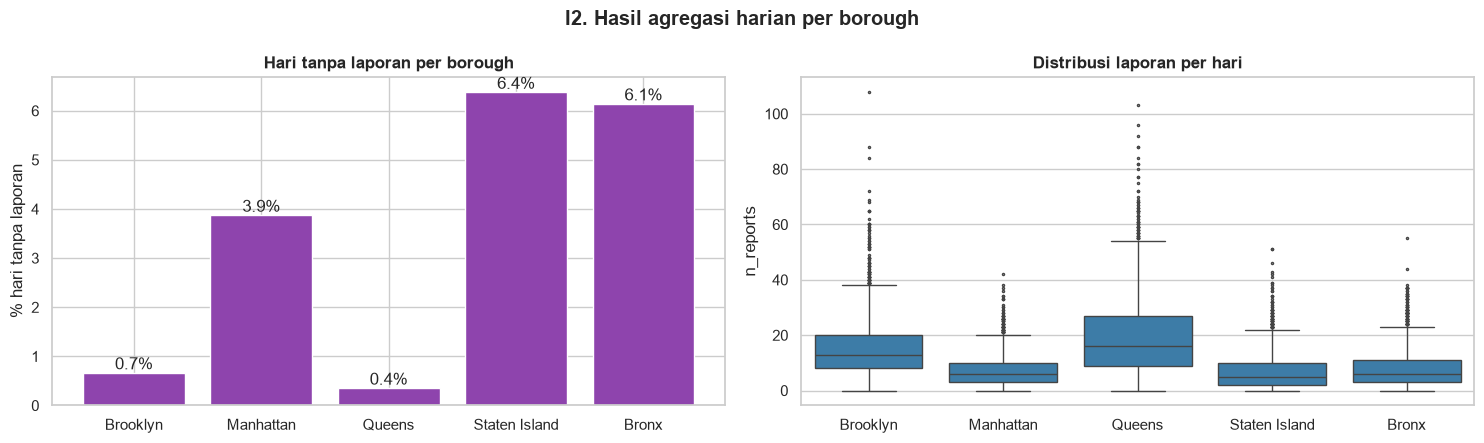

In [7]:
grid = pd.MultiIndex.from_product([pd.date_range(START, END, freq="D"), sorted(BORO_NAME)], names=["date", "Boro"])
daily.index = daily.index.set_levels(daily.index.levels[1].astype(str), level="Boro")
daily = daily.reindex(grid)

daily["no_reports"] = daily["n_reports"].isna()
daily["n_reports"] = daily["n_reports"].fillna(0).astype(int)
print(f"Grid: {len(daily):,} baris | hari-borough tanpa laporan: {daily['no_reports'].sum():,} "
      f"({daily['no_reports'].mean()*100:.1f}%)")

zero = daily.groupby(level="Boro")["no_reports"].mean().mul(100).rename(index=BORO_NAME)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(zero.index, zero.values, color="#8e44ad")
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%")
axes[0].set_ylabel("% hari tanpa laporan"); axes[0].set_title("Hari tanpa laporan per borough")
d = daily.reset_index().assign(Borough=lambda x: x["Boro"].map(BORO_NAME))
sns.boxplot(data=d, x="Borough", y="n_reports", ax=axes[1], color="#2c7fb8", fliersize=1.5)
axes[1].set_title("Distribusi laporan per hari"); axes[1].set_xlabel("")
fig.suptitle("I2. Hasil agregasi harian per borough", fontweight="bold")
plt.tight_layout()
savefig("I2_daily_aggregation")
plt.show()

**Masalah baru dari agregasi:** pada hari tanpa laporan, fitur seperti `median_repair_days` atau `pct_src_ctz` **tidak terdefinisi** (rata-rata dari 0 data), sehingga nilainya NaN. Ini bukan data hilang karena error, melainkan konsekuensi agregasi.

**Penanganan:** `n_reports` diisi 0 (nilai sebenarnya). Fitur rasio/rata-rata diisi **median borough yang sama pada bulan yang sama** (kondisi operasional paling mirip). Hari-hari ini diberi flag `no_reports`.

In [8]:
COND_COLS = [c for c in daily.columns if c not in ("n_reports", "no_reports")]
boro_lvl = daily.index.get_level_values("Boro")
month_lvl = daily.index.get_level_values("date").to_period("M")

na_before = daily[COND_COLS].isna().sum().sum()
for c in COND_COLS:
    daily[c] = (daily[c]
                .fillna(daily.groupby([boro_lvl, month_lvl])[c].transform("median"))
                .fillna(daily.groupby(boro_lvl)[c].transform("median")))
print(f"NaN fitur kondisional: {na_before:,} → {daily[COND_COLS].isna().sum().sum()}")

NaN fitur kondisional: 5,785 → 0


## 5. Fitur Cuaca Turunan

Lubang jalan terbentuk ketika air meresap ke retakan aspal, **membeku dan memuai**, lalu mencair. Karena itu fitur siklus beku-cair dan akumulasi beberapa hari lebih relevan daripada cuaca pada hari yang sama.

| Fitur | Rumus |
|---|---|
| `temp_mean`, `temp_range` | (max + min)/2, max − min |
| `freeze_thaw` | 1 jika suhu min < 0 °C **dan** max > 0 °C |
| `precip_7d`, `snow_7d` | Total presipitasi / salju 7 hari terakhir |
| `freeze_thaw_7d`, `freeze_thaw_28d` | Jumlah hari beku-cair 7 / 28 hari terakhir |
| `precip_lag1`, `precip_lag3` | Presipitasi 1 / 3 hari sebelumnya |

In [9]:
wf = weather.set_index("date").sort_index().rename(columns={
    "temperature_2m_max": "temp_max", "temperature_2m_min": "temp_min",
    "precipitation_sum": "precip", "rain_sum": "rain", "snowfall_sum": "snow"})

wf["temp_mean"]  = (wf["temp_max"] + wf["temp_min"]) / 2
wf["temp_range"] = wf["temp_max"] - wf["temp_min"]
wf["freeze_thaw"] = ((wf["temp_min"] < 0) & (wf["temp_max"] > 0)).astype(int)

# min_periods = ukuran window: hari awal yang window-nya belum lengkap dibiarkan NaN (bukan diisi 0)
wf["precip_7d"]       = wf["precip"].rolling(7, min_periods=7).sum()
wf["snow_7d"]         = wf["snow"].rolling(7, min_periods=7).sum()
wf["freeze_thaw_7d"]  = wf["freeze_thaw"].rolling(7, min_periods=7).sum()
wf["freeze_thaw_28d"] = wf["freeze_thaw"].rolling(28, min_periods=28).sum()
wf["precip_lag1"] = wf["precip"].shift(1)
wf["precip_lag3"] = wf["precip"].shift(3)

FIRST_COMPLETE = wf.dropna().index.min()
print("Hari pertama dengan semua window lengkap:", FIRST_COMPLETE.date())
print("Hari beku-cair total:", wf["freeze_thaw"].sum())
wf.describe().T[["mean", "std", "min", "max"]]

Hari pertama dengan semua window lengkap: 2018-01-28
Hari beku-cair total: 492


,mean,std,min,max
temp_max,17.201,9.708,-12.700,37.600
temp_min,8.506,9.224,-20.500,26.300
precip,3.801,8.303,0.000,111.500
rain,3.583,8.129,0.000,111.500
snow,0.153,1.200,0.000,27.020
temp_mean,12.854,9.343,-15.150,31.950
temp_range,8.695,3.083,1.300,25.500
freeze_thaw,0.192,0.394,0.000,1.000
precip_7d,26.611,23.031,0.000,155.600
snow_7d,1.054,3.701,0.000,35.630


## 6. Merge, Tuple Duplication & Data Value Conflict

In [10]:
merged = daily.reset_index().merge(wf.reset_index(), on="date", how="left",
                                   validate="many_to_one", indicator=True)
print(merged["_merge"].value_counts().to_dict())
assert (merged["_merge"] == "both").all(), "Ada tanggal pothole tanpa pasangan cuaca"
merged = merged.drop(columns="_merge")

# Buang 27 hari pertama 2018 yang window rolling-nya belum lengkap
n0 = len(merged)
merged = merged[merged["date"] >= FIRST_COMPLETE].reset_index(drop=True)
print(f"Buang hari dengan window belum lengkap: {n0:,} → {len(merged):,} baris")

# Tuple duplication: kunci (date, Boro) harus unik
print("Duplikat (date, Boro):", merged.duplicated(["date", "Boro"]).sum())
print("Total NaN:", int(merged.isna().sum().sum()))

{'both': 12785, 'left_only': 0, 'right_only': 0}


Buang hari dengan window belum lengkap: 12,785 → 12,650 baris
Duplikat (date, Boro): 0
Total NaN: 0


In [11]:
# Atribut kalender (dipakai untuk analisis kategorikal, bukan fitur numerik korelasi)
SEASON = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
          6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}
merged["month"] = merged["date"].dt.month
merged["dow"] = merged["date"].dt.dayofweek
merged["is_weekend"] = merged["dow"] >= 5
merged["season"] = merged["month"].map(SEASON)
merged["Boro"] = merged["Boro"].astype("category")

merged.head()

,date,Boro,n_reports,mean_repair_days,median_repair_days,pct_same_day,pct_repair_outlier,pct_src_ctz,pct_by_YRD,pct_by_CSC,pct_by_SPH,pct_by_ONF,mean_shape_len_m,pct_has_specloc,pct_has_housenum,mean_entry_lag,no_reports,temp_max,temp_min,precip,rain,snow,precip_corrected,temp_mean,temp_range,freeze_thaw,precip_7d,snow_7d,freeze_thaw_7d,freeze_thaw_28d,precip_lag1,precip_lag3,month,dow,is_weekend,season
0,2018-01-28,B,32,2.062,2.000,0.000,0.000,0.781,0.219,0.375,0.312,0.094,142.511,0.375,0.469,0.438,False,10.700,5.300,4.100,4.100,0.000,False,8.000,5.400,0,12.100,0.000,4.000,13.000,0.000,0.000,1,6,True,Winter
1,2018-01-28,M,8,1.250,1.000,0.125,0.000,0.500,0.500,0.250,0.125,0.125,182.156,0.250,0.500,0.875,False,10.700,5.300,4.100,4.100,0.000,False,8.000,5.400,0,12.100,0.000,4.000,13.000,0.000,0.000,1,6,True,Winter
2,2018-01-28,Q,41,1.220,1.000,0.000,0.000,0.634,0.366,0.244,0.195,0.195,161.075,0.293,0.732,0.463,False,10.700,5.300,4.100,4.100,0.000,False,8.000,5.400,0,12.100,0.000,4.000,13.000,0.000,0.000,1,6,True,Winter
3,2018-01-28,S,12,2.000,2.000,0.000,0.000,0.917,0.083,0.167,0.750,0.000,176.076,0.167,1.000,0.083,False,10.700,5.300,4.100,4.100,0.000,False,8.000,5.400,0,12.100,0.000,4.000,13.000,0.000,0.000,1,6,True,Winter
4,2018-01-28,X,7,1.000,1.000,0.000,0.000,1.000,0.000,0.286,0.714,0.000,174.451,0.286,1.000,0.000,False,10.700,5.300,4.100,4.100,0.000,False,8.000,5.400,0,12.100,0.000,4.000,13.000,0.000,0.000,1,6,True,Winter


**Data value conflict** yang ditangani:

| Konflik | Penyelesaian |
|---|---|
| Panjang segmen dalam **feet**, sedangkan cuaca memakai satuan metrik | Dikonversi ke **meter** (`mean_shape_len_m`) |
| Salju Open-Meteo dalam **cm**, NOAA dalam **mm** | Disamakan ke cm saat verifikasi (notebook cleaning) |
| Presipitasi Open-Meteo vs observasi NOAA berbeda ekstrem pada 3 hari | Dikoreksi ke nilai NOAA (notebook cleaning, flag `precip_corrected`) |
| Cuaca 1 titik vs pothole 5 borough | Cuaca kota dipakai untuk semua borough (keterbatasan) |

## 7. Analisis Korelasi & Kovarians (Redundansi Atribut Numerik)

In [12]:
NUM_FEATURES = [
    # pothole
    "n_reports", "mean_repair_days", "median_repair_days", "pct_same_day", "pct_repair_outlier",
    "pct_src_ctz", "pct_by_YRD", "pct_by_CSC", "pct_by_SPH", "pct_by_ONF",
    "mean_shape_len_m", "pct_has_specloc", "pct_has_housenum", "mean_entry_lag",
    # cuaca
    "temp_max", "temp_min", "temp_mean", "temp_range", "precip", "rain", "snow",
    "freeze_thaw", "precip_7d", "snow_7d", "freeze_thaw_7d", "freeze_thaw_28d", "precip_lag1", "precip_lag3",
]
X = merged[NUM_FEATURES]
print(f"{len(NUM_FEATURES)} fitur numerik × {len(X):,} baris")

skew = X.skew().sort_values(key=abs, ascending=False)
print("Fitur paling skewed:", skew.head(6).round(1).to_dict())

28 fitur numerik × 12,650 baris
Fitur paling skewed: {'pct_repair_outlier': 22.1, 'snow': 13.1, 'mean_shape_len_m': 6.6, 'snow_7d': 5.3, 'rain': 4.2, 'precip_lag3': 4.1}


Banyak fitur **sangat skewed** (salju, presipitasi, durasi), sehingga hubungan antar-fitur dihitung dengan dua cara:
- **Pearson**: mengukur hubungan **linear** dan sensitif terhadap outlier
- **Spearman**: berbasis ranking, mengukur hubungan **monoton**, dan lebih robust untuk data skewed

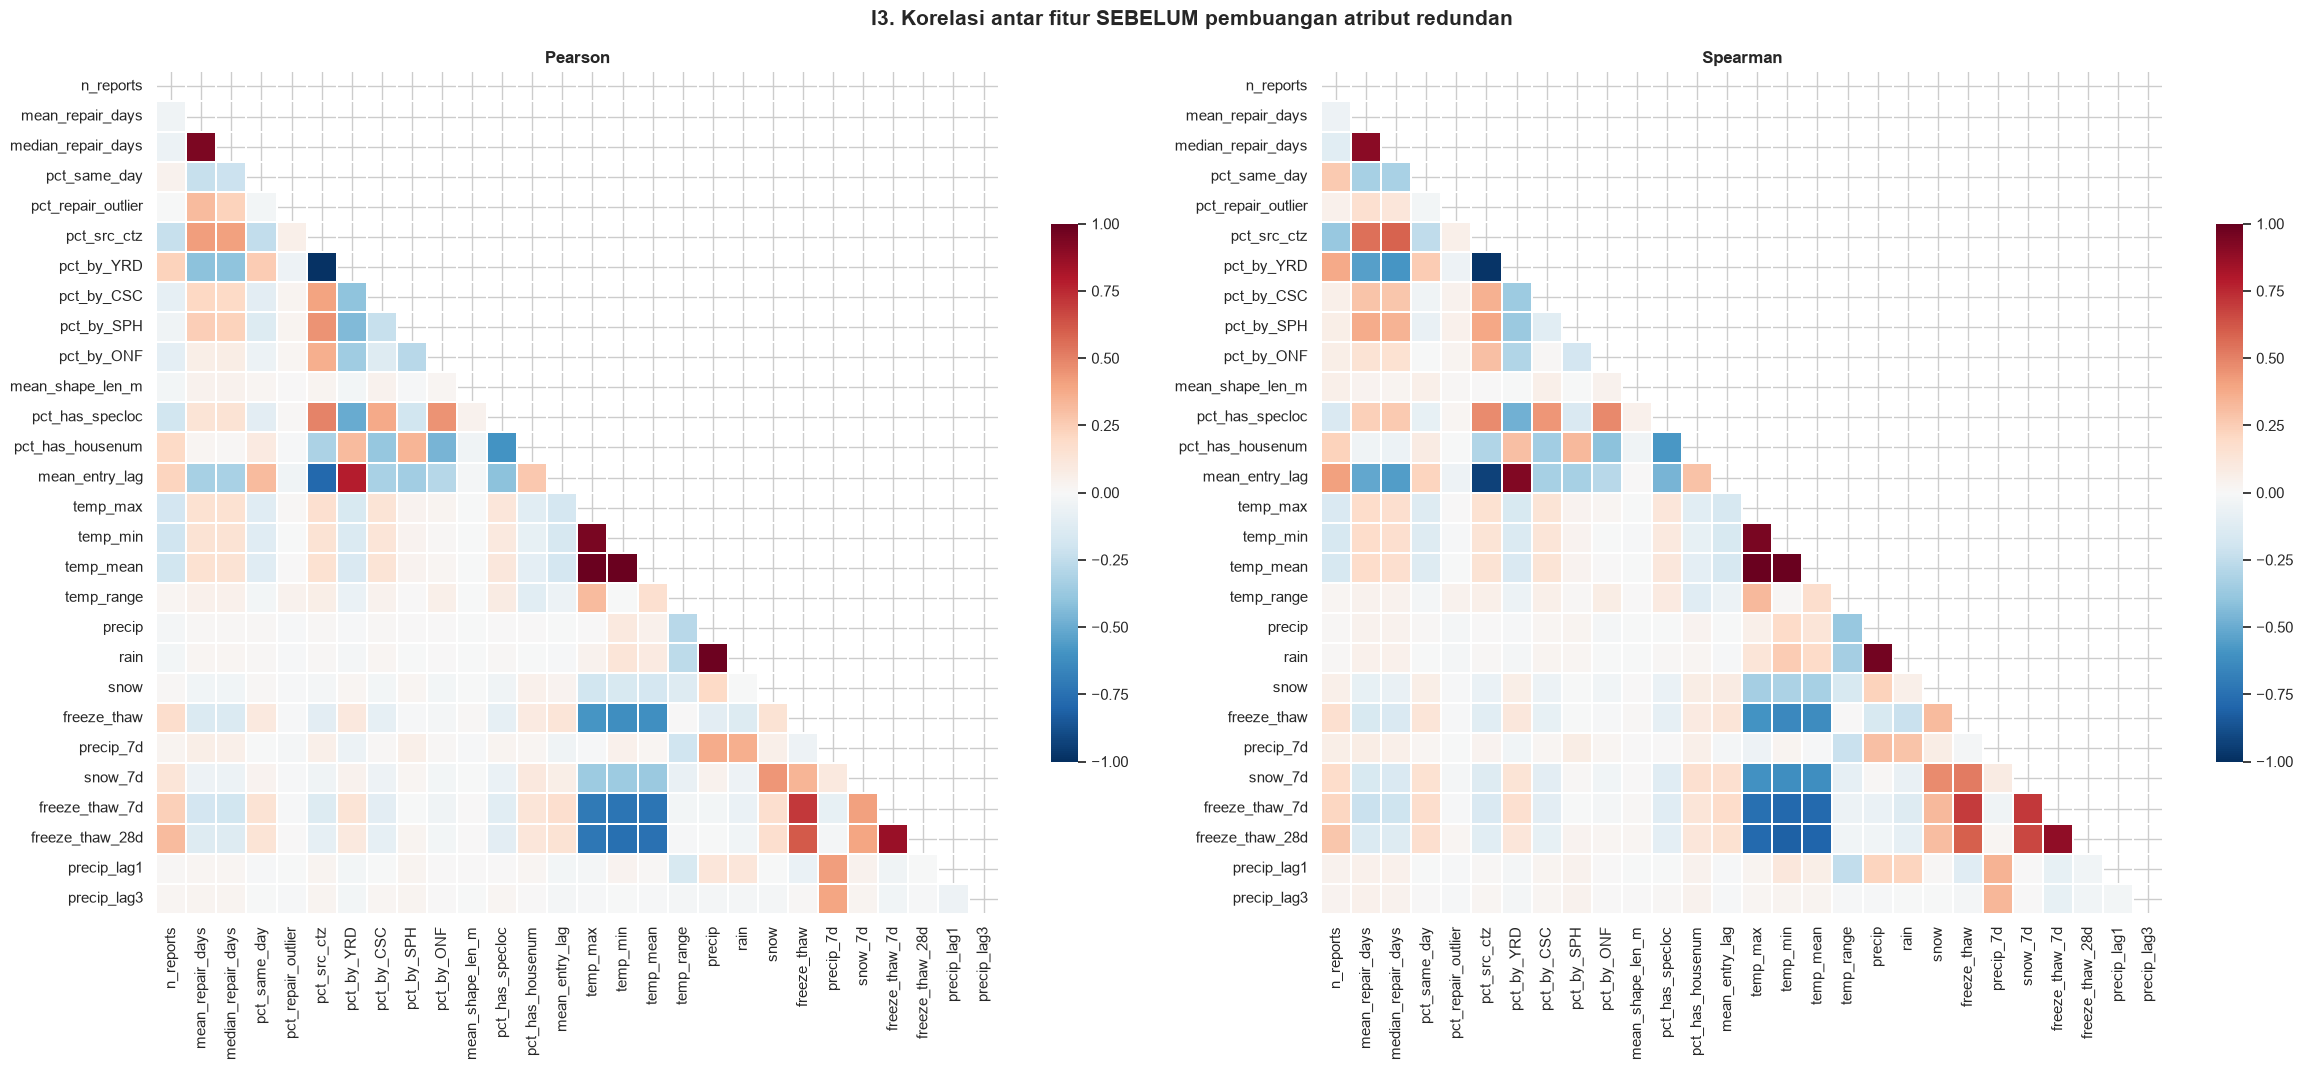

In [13]:
pearson  = X.corr(method="pearson")
spearman = X.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(24, 10.5))
mask = np.triu(np.ones_like(pearson, dtype=bool))
for ax, (name, c) in zip(axes, [("Pearson", pearson), ("Spearman", spearman)]):
    sns.heatmap(c, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
                linewidths=.3, cbar_kws={"shrink": .6}, ax=ax)
    ax.set_title(f"{name}")
fig.suptitle("I3. Korelasi antar fitur SEBELUM pembuangan atribut redundan", fontweight="bold", fontsize=15)
plt.tight_layout()
savefig("I3_correlation_before")
plt.show()

In [14]:
def high_pairs(c, thr):
    u = c.where(np.triu(np.ones(c.shape, dtype=bool), 1)).stack()
    return u[u.abs() > thr]

pairs = pd.concat({"pearson": pearson.stack(), "spearman": spearman.stack()}, axis=1)
cand = high_pairs(pearson, 0.7).index.union(high_pairs(spearman, 0.7).index)
pair_table = (pairs.loc[cand].assign(max_abs=lambda d: d.abs().max(axis=1))
                   .sort_values("max_abs", ascending=False))
pair_table["redundan (|r| > 0.85)"] = pair_table["max_abs"] > 0.85
pair_table.round(3)

,,pearson,spearman,max_abs,redundan (|r| > 0.85)
temp_max,temp_mean,0.987,0.987,0.987,True
temp_min,temp_mean,0.986,0.986,0.986,True
pct_src_ctz,pct_by_YRD,-0.985,-0.978,0.985,True
precip,rain,0.980,0.969,0.980,True
temp_max,temp_min,0.947,0.946,0.947,True
mean_repair_days,median_repair_days,0.941,0.900,0.941,True
pct_src_ctz,mean_entry_lag,-0.785,-0.934,0.934,True
pct_by_YRD,mean_entry_lag,0.785,0.928,0.928,True
freeze_thaw_7d,freeze_thaw_28d,0.866,0.887,0.887,True
temp_min,freeze_thaw_28d,-0.756,-0.814,0.814,False


### 7.1 Kovarians vs korelasi

Kovarians juga mengukur arah hubungan, tetapi **besarnya bergantung pada satuan**. Tabel di bawah menunjukkan variansi (diagonal kovarians) tiap fitur yang skalanya berbeda jauh. Karena itu, keputusan redundansi memakai **korelasi**, yaitu kovarians yang sudah dinormalisasi oleh standar deviasi:

$$r_{A,B} = \frac{\mathrm{Cov}(A,B)}{\sigma_A \, \sigma_B}$$

,variansi,std
mean_shape_len_m,"2,921.753",54.053
precip_7d,532.775,23.082
n_reports,115.398,10.742
pct_by_CSC,0.047,0.217
pct_same_day,0.030,0.174
pct_repair_outlier,0.000,0.020


Cov(z-score) == Pearson r : True


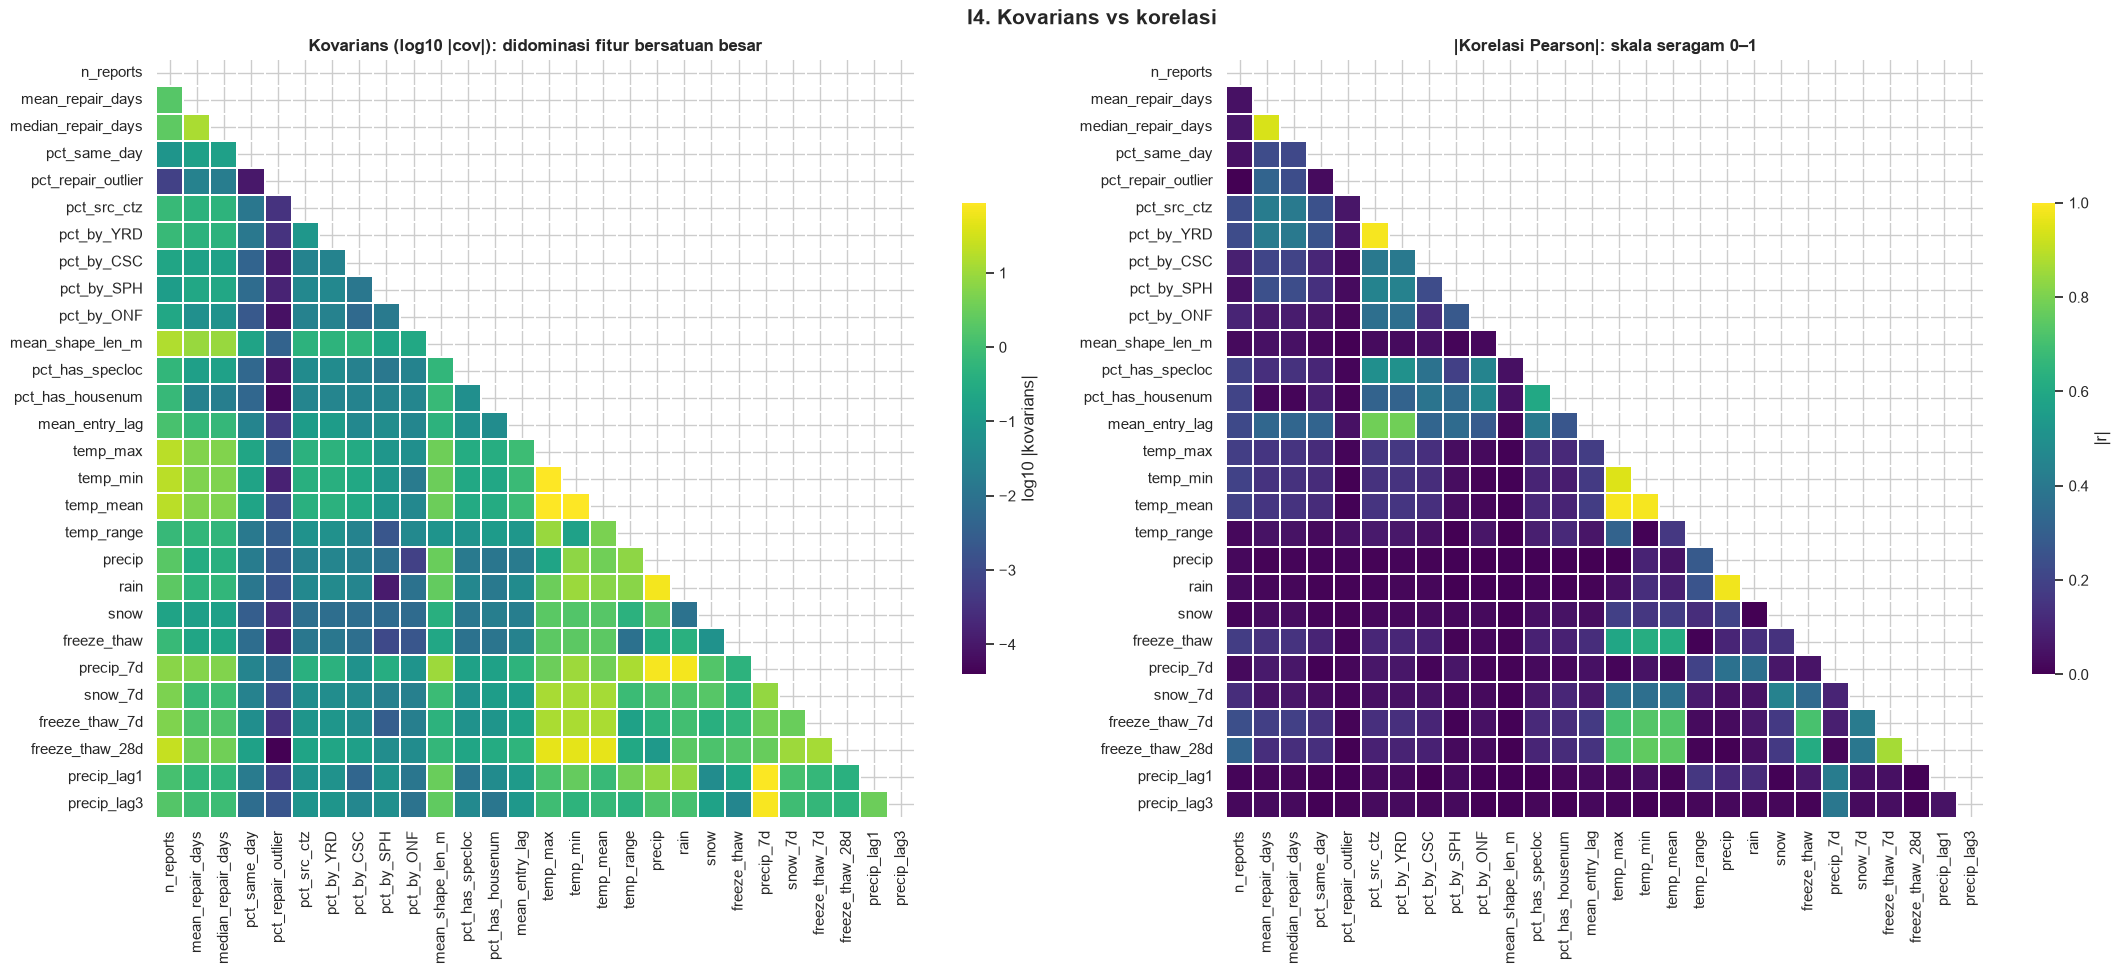

In [15]:
cov = X.cov()
var_table = pd.DataFrame({"variansi": np.diag(cov), "std": np.sqrt(np.diag(cov))}, index=NUM_FEATURES)
display(var_table.sort_values("variansi", ascending=False).iloc[[0, 1, 2, -3, -2, -1]])

# Bukti: kovarians dari data yang sudah distandardisasi = korelasi Pearson
Z = (X - X.mean()) / X.std()
print("Cov(z-score) == Pearson r :", np.allclose(Z.cov().values, pearson.values))

fig, axes = plt.subplots(1, 2, figsize=(22, 9.5))
sns.heatmap(np.log10(cov.abs() + 1e-6), mask=mask, cmap="viridis", square=True, linewidths=.3,
            cbar_kws={"shrink": .6, "label": "log10 |kovarians|"}, ax=axes[0])
axes[0].set_title("Kovarians (log10 |cov|): didominasi fitur bersatuan besar")
sns.heatmap(pearson.abs(), mask=mask, cmap="viridis", vmin=0, vmax=1, square=True, linewidths=.3,
            cbar_kws={"shrink": .6, "label": "|r|"}, ax=axes[1])
axes[1].set_title("|Korelasi Pearson|: skala seragam 0–1")
fig.suptitle("I4. Kovarians vs korelasi", fontweight="bold", fontsize=15)
plt.tight_layout()
savefig("I4_covariance_vs_correlation")
plt.show()

### 7.2 Visualisasi pasangan redundan

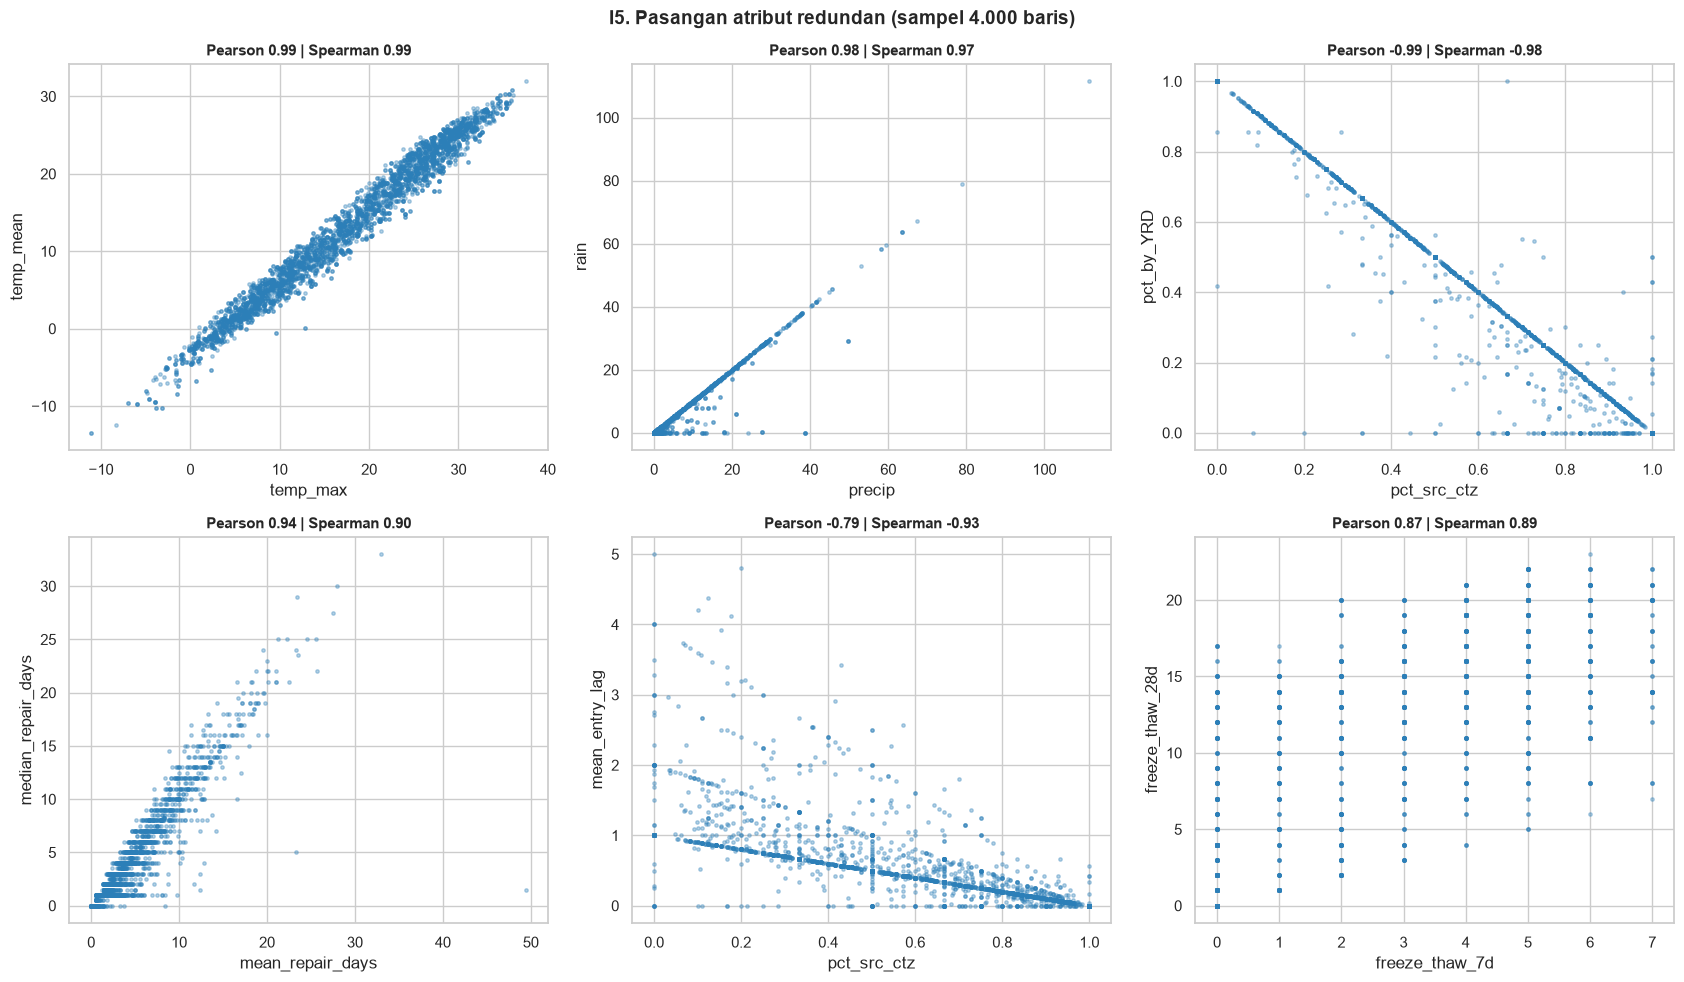

In [16]:
SHOW_PAIRS = [("temp_max", "temp_mean"), ("precip", "rain"), ("pct_src_ctz", "pct_by_YRD"),
              ("mean_repair_days", "median_repair_days"), ("pct_src_ctz", "mean_entry_lag"),
              ("freeze_thaw_7d", "freeze_thaw_28d")]
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
sample = merged.sample(4000, random_state=42)
for ax, (a, b) in zip(axes.flat, SHOW_PAIRS):
    ax.scatter(sample[a], sample[b], s=6, alpha=.35, color="#2c7fb8")
    ax.set_xlabel(a); ax.set_ylabel(b)
    ax.set_title(f"Pearson {pearson.loc[a, b]:.2f} | Spearman {spearman.loc[a, b]:.2f}", fontsize=11)
fig.suptitle("I5. Pasangan atribut redundan (sampel 4.000 baris)", fontweight="bold", fontsize=14)
plt.tight_layout()
savefig("I5_redundant_pairs")
plt.show()

### 7.3 Keputusan pembuangan atribut redundan

**Aturan:** jika |r| > 0,85 (Pearson **atau** Spearman), buang salah satu. Yang dipertahankan adalah fitur yang lebih **interpretatif, robust, atau sesuai konteks domain**.

| Dibuang | Redundan dengan | Alasan memilih yang dipertahankan |
|---|---|---|
| `temp_max`, `temp_min` | `temp_mean` (r ≈ 0,99) | `temp_mean` + `temp_range` merangkum informasi yang sama dan **tidak kolinear sempurna** |
| `rain` | `precip` (r ≈ 0,98) | `precip` = hujan + salju (lebih lengkap); keduanya hanya berbeda di hari bersalju |
| `pct_by_YRD` | `pct_src_ctz` (r ≈ −0,98) | Laporan non-warga hampir selalu ditangani unit YRD. `pct_src_ctz` lebih bermakna (sumber pelapor) |
| `mean_repair_days` | `median_repair_days` (r ≈ 0,90–0,94) | Median **robust** terhadap durasi ekstrem (distribusi sangat skewed) |
| `mean_entry_lag` | `pct_src_ctz` (Spearman ≈ −0,93) | Jeda input adalah artefak administratif dari sumber laporan |
| `freeze_thaw_7d` | `freeze_thaw_28d` (r ≈ 0,87–0,89) | Korelasi beku-cair → laporan naik tajam sampai lag ±3 minggu lalu mendatar (bagian 10), sehingga akumulasi 4 minggu lebih relevan daripada 1 minggu |

In [17]:
DROP_REDUNDANT = {
    "temp_max": "redundan dengan temp_mean",
    "temp_min": "redundan dengan temp_mean",
    "rain": "redundan dengan precip",
    "pct_by_YRD": "redundan dengan pct_src_ctz",
    "mean_repair_days": "redundan dengan median_repair_days",
    "mean_entry_lag": "redundan dengan pct_src_ctz",
    "freeze_thaw_7d": "redundan dengan freeze_thaw_28d",
}
KEEP = [f for f in NUM_FEATURES if f not in DROP_REDUNDANT]

# Verifikasi: tidak ada lagi pasangan |r| > 0.85
left_p = high_pairs(X[KEEP].corr("pearson"), 0.85)
left_s = high_pairs(X[KEEP].corr("spearman"), 0.85)
print(f"Fitur: {len(NUM_FEATURES)} → {len(KEEP)}")
print("Pasangan |r| > 0.85 tersisa — Pearson:", len(left_p), "| Spearman:", len(left_s))
print("|r| maksimum tersisa: Pearson {:.3f}, Spearman {:.3f}".format(
    high_pairs(X[KEEP].corr("pearson"), 0).abs().max(), high_pairs(X[KEEP].corr("spearman"), 0).abs().max()))

Fitur: 28 → 21
Pasangan |r| > 0.85 tersisa — Pearson: 0 | Spearman: 0
|r| maksimum tersisa: Pearson 0.748, Spearman 0.802


## 8. Multikolinearitas: Variance Inflation Factor (VIF)

Korelasi hanya melihat **pasangan**, sedangkan VIF mendeteksi fitur yang bisa diprediksi dari **kombinasi beberapa fitur lain**:

$$\mathrm{VIF}_j = \frac{1}{1 - R_j^2}$$

VIF > 10 menandakan multikolinearitas serius. Jika fitur adalah **kombinasi linear sempurna** dari fitur lain (mis. `temp_mean` = (`temp_max` + `temp_min`)/2 dan `temp_range` = `temp_max` − `temp_min`), secara teori VIF = ∞. Secara numerik hasilnya menjadi sangat besar (ribuan hingga jutaan).

In [18]:
def vif_table(frame):
    Xc = add_constant(frame.astype(float))
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                     index=frame.columns, name="VIF")

vif_before = vif_table(X)
vif_after  = vif_table(X[KEEP])
vif = pd.concat({"sebelum": vif_before, "sesudah": vif_after}, axis=1).sort_values("sebelum", ascending=False)
vif.round(2)

,sebelum,sesudah
temp_range,"3,345,096.040",1.220
rain,"2,778,352.250",NaN
precip,"710,849.480",1.370
snow,"150,823.550",1.310
temp_max,"91,802.930",NaN
temp_min,"37,840.070",NaN
temp_mean,"33,082.150",2.790
pct_src_ctz,40.270,8.180
pct_by_YRD,34.940,NaN
mean_repair_days,9.880,NaN


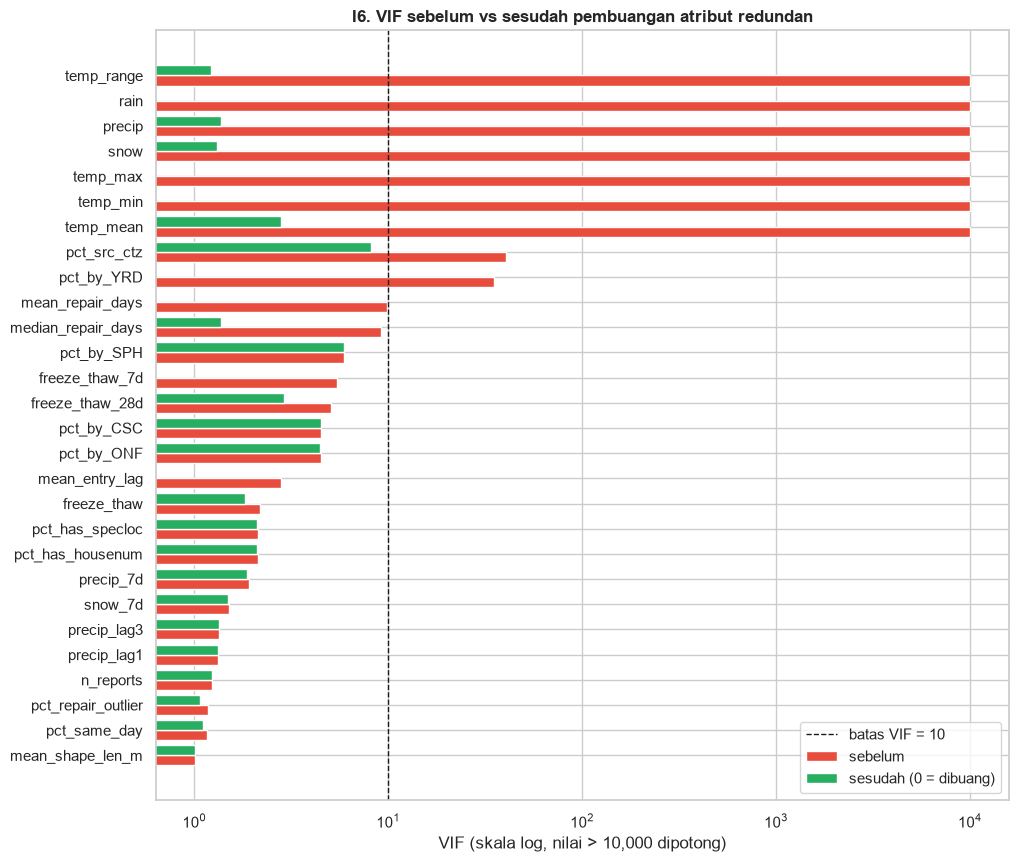

Fitur dengan VIF > 10 sesudah: {}


In [19]:
CAP = 1e4
plot = vif.clip(upper=CAP).fillna(0)
fig, ax = plt.subplots(figsize=(11, 10))
y = np.arange(len(plot))
ax.barh(y + .2, plot["sebelum"], height=.4, color="#e74c3c", label="sebelum")
ax.barh(y - .2, plot["sesudah"], height=.4, color="#27ae60", label="sesudah (0 = dibuang)")
ax.set_yticks(y, plot.index); ax.invert_yaxis()
ax.set_xscale("log")
ax.axvline(10, color="k", ls="--", lw=1, label="batas VIF = 10")
ax.set_xlabel(f"VIF (skala log, nilai > {CAP:,.0f} dipotong)")
ax.set_title("I6. VIF sebelum vs sesudah pembuangan atribut redundan")
ax.legend(loc="lower right")
savefig("I6_vif_before_after")
plt.show()

print("Fitur dengan VIF > 10 sesudah:", vif_after[vif_after > 10].round(2).to_dict())

**Interpretasi VIF:**
- **Sebelum:** ada dua kelompok kolinear sempurna. (1) `temp_max`, `temp_min`, `temp_mean`, `temp_range`: keempatnya saling menentukan. (2) `precip`, `rain`, `snow`: presipitasi = hujan + setara-air salju. Karena itu `snow` ikut ber-VIF sangat besar walaupun korelasi pasangannya dengan `precip` rendah. **Ini hal yang tidak terdeteksi oleh korelasi berpasangan**, dan menunjukkan kenapa VIF diperlukan.
- **Sesudah:** semua VIF < 10. Nilai tertinggi `pct_src_ctz` (±8) masih wajar karena berkaitan dengan komposisi instansi penangan (`pct_by_*`).

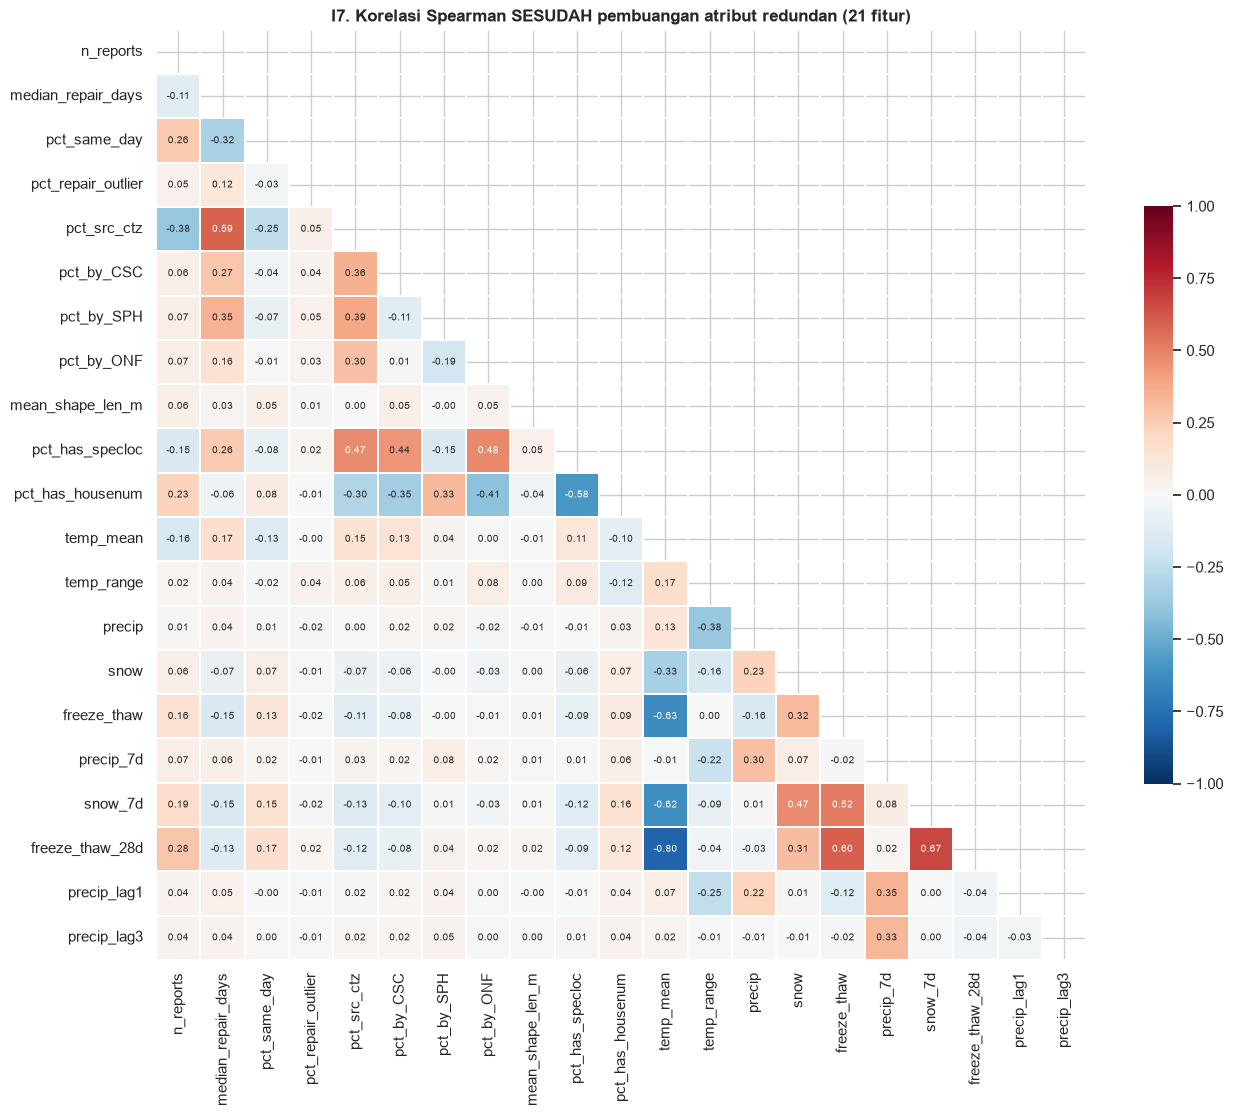

In [20]:
fig, ax = plt.subplots(figsize=(15, 12.5))
c_after = X[KEEP].corr("spearman")
sns.heatmap(c_after, mask=np.triu(np.ones_like(c_after, dtype=bool)), annot=True, fmt=".2f",
            annot_kws={"size": 7.5}, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            linewidths=.3, cbar_kws={"shrink": .6}, ax=ax)
ax.set_title(f"I7. Korelasi Spearman SESUDAH pembuangan atribut redundan ({len(KEEP)} fitur)")
savefig("I7_correlation_after")
plt.show()

## 9. Redundansi Atribut Kategorikal: Uji Chi-Square

Untuk atribut **nominal**, korelasi tidak bisa dipakai, sehingga digunakan uji **χ² (chi-square) independensi** pada level work order (2018–2024).
- H₀: kedua atribut **independen**
- Dengan n > 140 ribu, p-value hampir selalu ≈ 0, sehingga **kekuatan hubungan** diukur dengan **Cramér's V** (0 = independen, 1 = saling menentukan).

$$V = \sqrt{\frac{\chi^2 / n}{\min(r-1,\,c-1)}}$$

In [21]:
wo = pothole.assign(season=pothole["date"].dt.month.map(SEASON))

def chi_square(a, b):
    ct = pd.crosstab(wo[a], wo[b])
    chi2, pval, dof, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / ct.values.sum() / (min(ct.shape) - 1))
    return {"atribut A": a, "atribut B": b, "chi2": chi2, "dof": dof, "p_value": pval, "cramers_v": v}

CAT_PAIRS = [("Source_group", "InitBy_group"), ("Boro", "InitBy_group"), ("Boro", "Source_group"),
             ("season", "InitBy_group"), ("season", "Source_group"), ("Boro", "season")]
chi_table = pd.DataFrame([chi_square(a, b) for a, b in CAT_PAIRS])
chi_table["kekuatan"] = pd.cut(chi_table["cramers_v"], [0, .1, .3, .5, 1],
                               labels=["lemah", "sedang", "kuat", "sangat kuat"])
chi_table.style.format({"chi2": "{:,.0f}", "p_value": "{:.2e}", "cramers_v": "{:.3f}"})

,atribut A,atribut B,chi2,dof,p_value,cramers_v,kekuatan
0,Source_group,InitBy_group,"158,610",8,0.00e+00,0.739,sangat kuat
1,Boro,InitBy_group,"12,067",16,0.00e+00,0.144,sedang
2,Boro,Source_group,"2,004",8,0.00e+00,0.083,lemah
3,season,InitBy_group,"5,997",12,0.00e+00,0.117,sedang
4,season,Source_group,"7,297",6,0.00e+00,0.158,sedang
5,Boro,season,989,12,5.26e-204,0.048,lemah


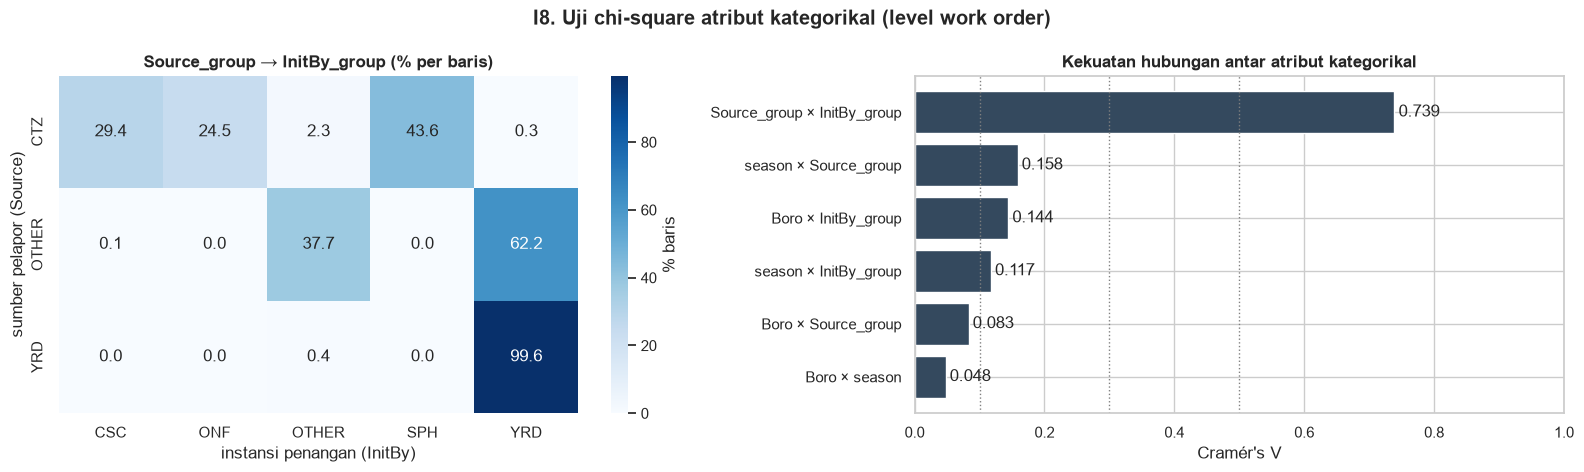

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
ct = pd.crosstab(wo["Source_group"], wo["InitBy_group"], normalize="index") * 100
sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% baris"}, ax=axes[0])
axes[0].set_title("Source_group → InitBy_group (% per baris)")
axes[0].set_xlabel("instansi penangan (InitBy)"); axes[0].set_ylabel("sumber pelapor (Source)")

t = chi_table.assign(pair=chi_table["atribut A"] + " × " + chi_table["atribut B"]).sort_values("cramers_v")
axes[1].barh(t["pair"], t["cramers_v"], color="#34495e")
axes[1].bar_label(axes[1].containers[0], fmt="%.3f", padding=3)
for x in (.1, .3, .5):
    axes[1].axvline(x, color="grey", ls=":", lw=1)
axes[1].set_xlim(0, 1); axes[1].set_xlabel("Cramér's V")
axes[1].set_title("Kekuatan hubungan antar atribut kategorikal")
fig.suptitle("I8. Uji chi-square atribut kategorikal (level work order)", fontweight="bold")
plt.tight_layout()
savefig("I8_chi_square")
plt.show()

**Interpretasi:** `Source_group` × `InitBy_group` memiliki hubungan **sangat kuat**. Laporan yang berasal dari unit YRD hampir seluruhnya ditangani YRD sendiri, sedangkan laporan warga (CTZ) disebar ke instansi lain. Ini konsisten dengan korelasi `pct_src_ctz` ↔ `pct_by_YRD` ≈ −0,98 di bagian 7, yang juga menjadi dasar pembuangan `pct_by_YRD`.

Pasangan lain berhubungan lemah–sedang, sehingga tidak dianggap redundan.

## 10. Insight Integrasi: Beku-Cair → Lubang Jalan

Setelah kedua sumber digabung, pertanyaan analisis bisa diuji: **apakah siklus beku-cair diikuti lonjakan laporan lubang jalan?** Korelasi dihitung di level mingguan (NYC total) dengan berbagai **jeda waktu (lag)**.

In [23]:
weekly = (merged.groupby("date").agg(n_reports=("n_reports", "sum"), freeze_thaw=("freeze_thaw", "first"),
                                     temp_mean=("temp_mean", "first"), precip=("precip", "first"))
                .resample("W").agg({"n_reports": "sum", "freeze_thaw": "sum", "temp_mean": "mean", "precip": "sum"}))

lags = range(0, 9)
xcorr = pd.DataFrame({
    "hari beku-cair": [weekly["n_reports"].corr(weekly["freeze_thaw"].shift(L), method="spearman") for L in lags],
    "suhu rata-rata": [weekly["n_reports"].corr(weekly["temp_mean"].shift(L), method="spearman") for L in lags],
    "presipitasi":    [weekly["n_reports"].corr(weekly["precip"].shift(L), method="spearman") for L in lags],
}, index=pd.Index(lags, name="lag (minggu)"))
display(xcorr.round(3))
# "Titik lutut": lag pertama yang korelasinya sudah mencapai >= 98% dari maksimum
ft = xcorr["hari beku-cair"]
KNEE = int(ft[ft >= 0.98 * ft.max()].index.min())
print(f"Korelasi beku-cair: lag 0 = {ft[0]:.3f} → lag {KNEE} = {ft[KNEE]:.3f} (sudah {ft[KNEE]/ft.max()*100:.0f}% dari maksimum {ft.max():.3f}), lalu mendatar")

,hari beku-cair,suhu rata-rata,presipitasi
lag (minggu),,,
0,0.435,-0.376,0.096
1,0.484,-0.447,0.106
2,0.543,-0.523,0.051
3,0.565,-0.568,0.044
4,0.572,-0.604,0.043
5,0.570,-0.637,0.001
6,0.570,-0.662,0.016
7,0.575,-0.688,0.045
8,0.570,-0.699,0.035


Korelasi beku-cair: lag 0 = 0.435 → lag 3 = 0.565 (sudah 98% dari maksimum 0.575), lalu mendatar


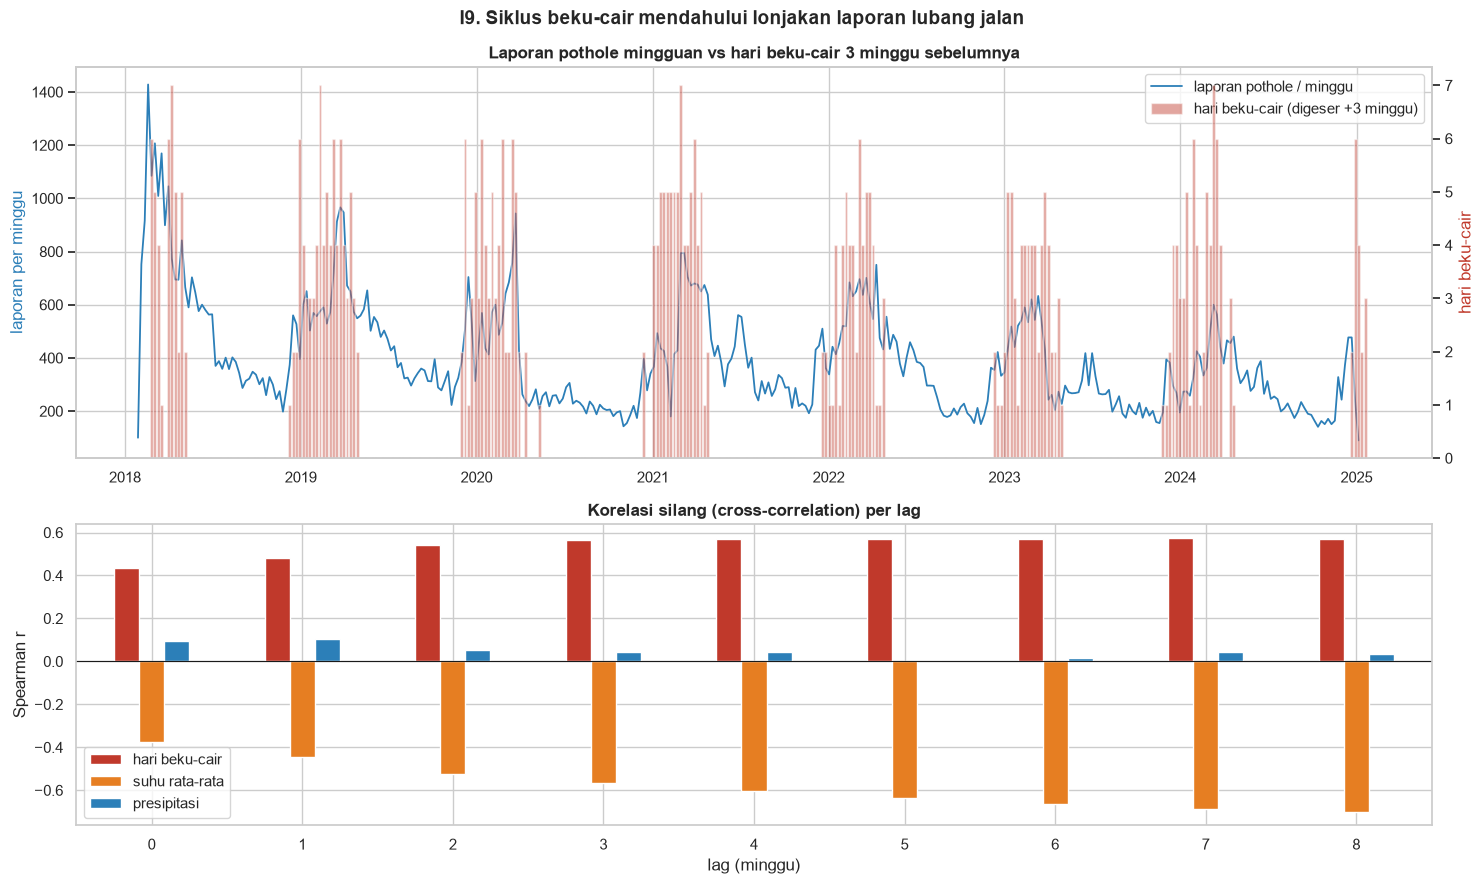

In [24]:
best = KNEE
fig, axes = plt.subplots(2, 1, figsize=(15, 9), gridspec_kw={"height_ratios": [1.3, 1]})

ax = axes[0]
ax.plot(weekly.index, weekly["n_reports"], color="#2c7fb8", lw=1.3, label="laporan pothole / minggu")
ax.set_ylabel("laporan per minggu", color="#2c7fb8")
ax2 = ax.twinx()
ax2.bar(weekly.index + pd.Timedelta(weeks=best), weekly["freeze_thaw"], width=6, color="#c0392b", alpha=.45,
        label=f"hari beku-cair (digeser +{best} minggu)")
ax2.set_ylabel("hari beku-cair", color="#c0392b"); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right")
ax.set_title(f"Laporan pothole mingguan vs hari beku-cair {best} minggu sebelumnya")

xcorr.plot.bar(ax=axes[1], color=["#c0392b", "#e67e22", "#2c7fb8"], rot=0)
axes[1].axhline(0, color="k", lw=.8)
axes[1].set_ylabel("Spearman r"); axes[1].set_title("Korelasi silang (cross-correlation) per lag")
fig.suptitle("I9. Siklus beku-cair mendahului lonjakan laporan lubang jalan", fontweight="bold", fontsize=14)
plt.tight_layout()
savefig("I9_freeze_thaw_lag")
plt.show()

**Insight:**
- Laporan lubang jalan berkorelasi positif dengan jumlah hari beku-cair. Korelasinya **naik tajam dari lag 0 sampai sekitar 3 minggu, lalu mendatar**, yang konsisten dengan proses fisik: retakan butuh beberapa minggu siklus beku-cair sebelum menjadi lubang dan dilaporkan.
- **Presipitasi hampir tidak berkorelasi** (r < 0,11), sehingga hujan saja bukan pemicu utama.
- Korelasi dengan suhu rata-rata (negatif) **terus menguat** hingga lag 8 minggu. Ini menunjukkan ada **efek musim** secara umum (musim dingin → banyak laporan), sehingga sebagian korelasi beku-cair juga mencerminkan musim, bukan hanya beku-cair itu sendiri.

Temuan ini menjadi alasan `freeze_thaw_28d` (akumulasi 4 minggu) dipertahankan di bagian 7.3.

> Korelasi ≠ kausalitas: musim dingin juga memengaruhi faktor lain (mis. jadwal inspeksi, anggaran perbaikan).

### 10.1 Uji kontrol musim: apakah hubungan ini hanya efek musim?

Musim dingin membawa **banyak hari beku-cair** dan juga **banyak laporan**, sehingga keduanya bisa berkorelasi hanya karena sama-sama mengikuti musim. Untuk mengujinya, korelasi dihitung ulang dengan beberapa cara yang mengontrol musim:

| Cara | Yang dikontrol |
|---|---|
| Minggu Desember–Maret saja | Membandingkan minggu-minggu di dalam musim dingin yang sama |
| Anomali terhadap rata-rata bulan kalender | Menghapus pola musiman rata-rata (mis. "Februari selalu tinggi") |
| Antar musim dingin | Musim dingin yang lebih banyak beku-cair → lebih banyak laporan? |

In [25]:
wk2 = weekly.assign(ft_lag=weekly["freeze_thaw"].shift(KNEE)).dropna(subset=["ft_lag"])
wk2["month"] = wk2.index.month
anom = wk2[["n_reports", "ft_lag"]] - wk2.groupby("month")[["n_reports", "ft_lag"]].transform("mean")
winter_wk = wk2[wk2["month"].isin([12, 1, 2, 3])]

# Per musim dingin: hari beku-cair Nov–Apr vs laporan Nov–Mei (label = tahun berakhirnya musim)
def winter_label(d):
    return np.where(d.month >= 11, d.year + 1, d.year)

wf_w = wf.loc[wf.index.month.isin([11, 12, 1, 2, 3, 4]), ["freeze_thaw", "snow"]]
wf_w = wf_w.groupby(winter_label(wf_w.index)).sum()
rep = pothole.loc[pothole["date"].dt.month.isin([11, 12, 1, 2, 3, 4, 5]), "date"]
rep = rep.groupby(winter_label(rep.dt)).size()
per_winter = (pd.DataFrame({"hari_beku_cair": wf_w["freeze_thaw"], "salju_cm": wf_w["snow"], "laporan_nov_mei": rep})
                .loc[START.year + 1:END.year])
display(per_winter)

season_test = pd.Series({
    "semua minggu (lag {} mgg)".format(KNEE): wk2["n_reports"].corr(wk2["ft_lag"], method="spearman"),
    "minggu Des–Mar saja":                    winter_wk["n_reports"].corr(winter_wk["ft_lag"], method="spearman"),
    "anomali thd rata-rata bulan":            anom["n_reports"].corr(anom["ft_lag"], method="spearman"),
    f"antar musim dingin (n={len(per_winter)})": per_winter["laporan_nov_mei"].corr(per_winter["hari_beku_cair"], method="spearman"),
}, name="Spearman r").round(3)
season_test.to_frame()

,hari_beku_cair,salju_cm,laporan_nov_mei
2019,81,58.940,16875
2020,71,29.680,13054
2021,78,84.910,13470
2022,59,48.370,14509
2023,63,25.620,11346
2024,67,38.220,10577


,Spearman r
semua minggu (lag 3 mgg),0.565
minggu Des–Mar saja,0.288
anomali thd rata-rata bulan,0.092
antar musim dingin (n=6),0.371


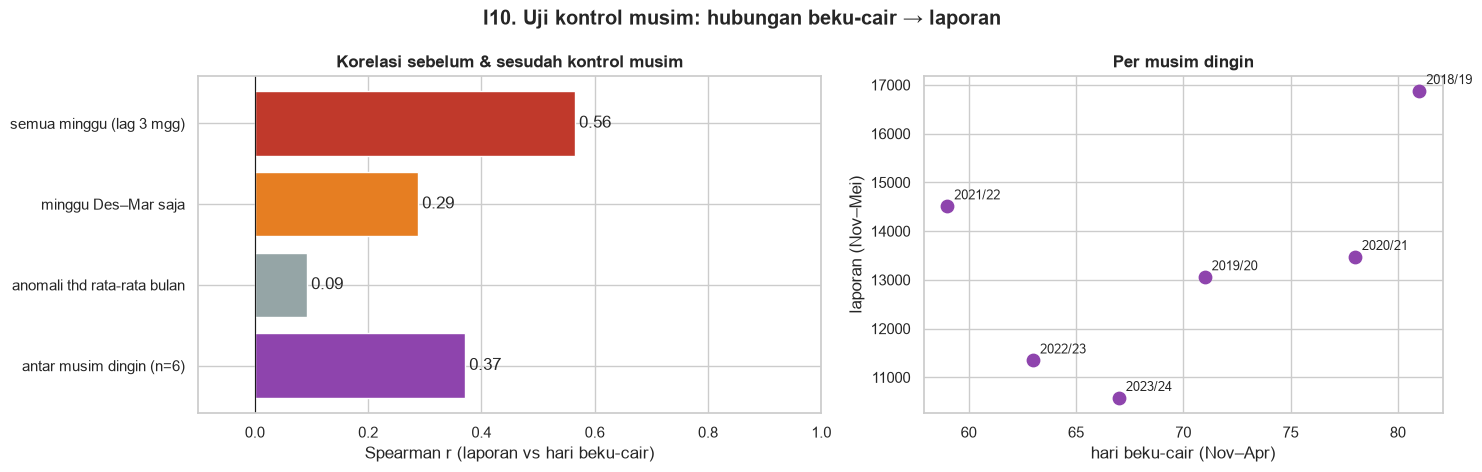

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
colors = ["#c0392b", "#e67e22", "#95a5a6", "#8e44ad"]
axes[0].barh(season_test.index[::-1], season_test.values[::-1], color=colors[::-1])
axes[0].bar_label(axes[0].containers[0], fmt="%.2f", padding=3)
axes[0].axvline(0, color="k", lw=.8); axes[0].set_xlim(-0.1, 1)
axes[0].set_xlabel("Spearman r (laporan vs hari beku-cair)")
axes[0].set_title("Korelasi sebelum & sesudah kontrol musim")

axes[1].scatter(per_winter["hari_beku_cair"], per_winter["laporan_nov_mei"], s=80, color="#8e44ad")
for yr, r in per_winter.iterrows():
    axes[1].annotate(f"{yr-1}/{str(yr)[2:]}", (r["hari_beku_cair"], r["laporan_nov_mei"]),
                     xytext=(5, 5), textcoords="offset points", fontsize=9)
axes[1].set_xlabel("hari beku-cair (Nov–Apr)"); axes[1].set_ylabel("laporan (Nov–Mei)")
axes[1].set_title("Per musim dingin")
fig.suptitle("I10. Uji kontrol musim: hubungan beku-cair → laporan", fontweight="bold")
plt.tight_layout()
savefig("I10_season_control")
plt.show()

**Kesimpulan uji kontrol musim:**
- Korelasi mingguan yang tinggi **sebagian besar adalah pola musim**: musim dingin → beku-cair banyak **dan** laporan banyak.
- **Di dalam musim dingin** (Des–Mar), minggu dengan lebih banyak beku-cair tetap diikuti lebih banyak laporan (korelasi sedang). Jadi ada hubungan yang bertahan setelah musim dikontrol.
- Setelah pola rata-rata tiap bulan dihapus, korelasinya hampir hilang. Variasi minggu-ke-minggu di luar pola musiman hanya sedikit dijelaskan oleh beku-cair.
- Antar musim dingin hubungannya positif, tetapi hanya 6 titik data dan jumlah laporan juga cenderung menurun dari tahun ke tahun (faktor lain, mis. kebijakan/perbaikan jalan), sehingga tidak bisa disimpulkan kuat.

**Rumusan akhir:** kedua dataset **jelas berhubungan melalui pola musiman**, dan beku-cair memberi sinyal tambahan yang lemah–sedang di dalam musim dingin. Karena data bersifat observasional, hasil ini adalah **asosiasi, bukan bukti sebab-akibat**.

## 11. Ringkasan Redundansi Level Atribut (dari Cleaning + Integrasi)

| Atribut | Redundan dengan | Bukti | Keputusan |
|---|---|---|---|
| `Boro` | prefix `DefNum` | 100% konsisten (0 konflik) | `Boro` dipertahankan, `DefNum` sebagai ID |
| `Boro` | digit-1 `OFT` | 2 konflik (segmen perbatasan) | Flag `boro_conflict` |
| `OnFaceName` | `OnPrimName` | singkatan vs nama lengkap | `OnFaceName` dibuang (cleaning) |
| `OnPrimName`/`FrmPrimNam`/`ToPrimName` | kode jalan di `OFT` | 10.707 kode, 0 konflik nama | `OFT` sebagai kunci, nama untuk keterbacaan |
| `the_geom` | `lon`, `lat` | geometri diringkas jadi titik tengah | `the_geom` dibuang (cleaning) |
| `Source_group` | `InitBy_group` | Cramér's V = 0,74 | `pct_by_YRD` dibuang |
| `temp_max`, `temp_min` | `temp_mean` | \|r\| > 0,85 | dibuang (integrasi) |
| `rain` | `precip` | \|r\| > 0,85 | dibuang (integrasi) |
| `pct_by_YRD`, `mean_entry_lag` | `pct_src_ctz` | \|r\| > 0,85 | dibuang (integrasi) |
| `mean_repair_days` | `median_repair_days` | \|r\| > 0,85 | dibuang (integrasi) |
| `freeze_thaw_7d` | `freeze_thaw_28d` | \|r\| > 0,85 | dibuang (integrasi) |

## 12. Simpan Hasil Integrasi

In [27]:
ID_COLS  = ["date", "Boro"]
CAL_COLS = ["month", "dow", "is_weekend", "season"]
FLAG_COLS = ["no_reports", "precip_corrected"]

integrated_full = merged[ID_COLS + CAL_COLS + FLAG_COLS + NUM_FEATURES]
integrated      = merged[ID_COLS + CAL_COLS + FLAG_COLS + KEEP]

integrated_full.to_parquet(OUT_DIR / "integrated_daily_full.parquet", index=False)
integrated.to_parquet(OUT_DIR / "integrated_daily.parquet", index=False)
integrated.to_csv(OUT_DIR / "integrated_daily.csv", index=False, date_format="%Y-%m-%d")

print("integrated_daily_full :", integrated_full.shape, "(semua fitur, untuk referensi)")
print("integrated_daily      :", integrated.shape, "(setelah buang redundan → input data_reduction)")
print("NaN:", int(integrated.isna().sum().sum()), "| duplikat (date, Boro):", integrated.duplicated(ID_COLS).sum())

integrated_daily_full : (12650, 36) (semua fitur, untuk referensi)
integrated_daily      : (12650, 29) (setelah buang redundan → input data_reduction)
NaN: 0 | duplikat (date, Boro): 0


In [28]:
pd.DataFrame({
    "tahap": ["work order bersih (semua tahun)", "filter periode cuaca", "agregasi hari × borough (grid)",
              "buang window rolling belum lengkap", "fitur numerik awal", "setelah buang redundan"],
    "nilai": [f"{N_CLEAN:,} baris", f"{len(pothole):,} baris", f"{len(daily):,} baris",
              f"{len(merged):,} baris", f"{len(NUM_FEATURES)} fitur", f"{len(KEEP)} fitur"],
})

,tahap,nilai
0,work order bersih (semua tahun),"400,961 baris"
1,filter periode cuaca,"145,279 baris"
2,agregasi hari × borough (grid),"12,785 baris"
3,buang window rolling belum lengkap,"12,650 baris"
4,fitur numerik awal,28 fitur
5,setelah buang redundan,21 fitur


**Output:**
| File | Isi |
|---|---|
| `output/integrated_daily.parquet` / `.csv` | 1 baris = 1 hari × 1 borough, fitur numerik **tanpa redundansi**. **Input `data_reduction.ipynb`** |
| `output/integrated_daily_full.parquet` | Sama, tetapi dengan semua fitur (termasuk yang redundan), untuk referensi |

**Langkah berikutnya:** `data_reduction.ipynb`, yaitu transformasi log, standardisasi, dan PCA.